Sistem ini bekerja dengan cara:
- OCSVM menilai data mentah dan memberikan "Skor Anomali" (Opini Dokter Umum).
- XGBoost menerima data mentah DITAMBAH Skor Anomali tersebut untuk membuat keputusan final (Opini Dokter Spesialis).

In [23]:
import pandas as pd
import numpy as np
import joblib
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import OneClassSVM
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

In [24]:
# LOAD DATA
try:
    df = pd.read_csv('ai4i2020.csv')
except FileNotFoundError:
    print("❌ Error: File 'ai4i2020.csv' tidak ditemukan.")
    exit()

# Hapus kolom ID dan label error spesifik (kita hanya pakai Machine failure)
df_clean = df.drop(['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'], axis=1)

# One-Hot Encoding untuk 'Type'
df_encoded = pd.get_dummies(df_clean, columns=['Type'], dtype=int)

In [25]:
# LOAD MODEL OCSVM LAMA 
print("\n📦 Memuat Model OCSVM dari Penelitian Sebelumnya...")

try:
    # Load Model & Scaler Lama (Pastikan file ini ada!)
    ocsvm = joblib.load('model_ocsvm.pkl')
    scaler_ocsvm = joblib.load('scaler.pkl') 
    
    # Definisikan urutan fitur yang dipakai OCSVM lama
    cols_ocsvm_numeric = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
    features_ocsvm = cols_ocsvm_numeric + ['Type_H', 'Type_L', 'Type_M']
    
    print("✅ Model OCSVM & Scaler Lama Berhasil Dimuat.")

except FileNotFoundError:
    print("❌ Error: File 'model_ocsvm.pkl' atau 'scaler.pkl' tidak ditemukan.")
    print("   Harap jalankan notebook analisis anomali Anda yang dulu untuk membuatnya.")
    raise # Hentikan proses


📦 Memuat Model OCSVM dari Penelitian Sebelumnya...
✅ Model OCSVM & Scaler Lama Berhasil Dimuat.


In [26]:
# GENERATE FITUR BARU ('Anomaly_Score')
print("✨ Menghitung Skor Anomali untuk seluruh dataset...")

# Siapkan data khusus untuk OCSVM (Urutan kolom harus sama persis)
X_for_ocsvm = df_encoded[features_ocsvm].copy()

# Scaling menggunakan Scaler LAMA (Penting!)
# Kita scale kolom numeriknya saja, kolom Type (0/1) biasanya dibiarkan atau ikut di-transform tergantung cara training lama.
# Asumsi: Scaler lama dilatih hanya pada kolom numerik.
X_for_ocsvm[cols_ocsvm_numeric] = scaler_ocsvm.transform(X_for_ocsvm[cols_ocsvm_numeric])
anomaly_scores = ocsvm.decision_function(X_for_ocsvm)

df_encoded['Anomaly_Score'] = anomaly_scores
print(f"   Contoh Skor: Min={anomaly_scores.min():.2f}, Max={anomaly_scores.max():.2f}")

✨ Menghitung Skor Anomali untuk seluruh dataset...
   Contoh Skor: Min=-188.80, Max=62.98


In [27]:
# 5. TRAINING XGBOOST (DENGAN DATA HYBRID)
# ==========================================
print("\n🚀 [Phase 2] Training XGBoost Hybrid...")

# Pisahkan X dan y
# X sekarang memiliki kolom tambahan: 'Anomaly_Score'
X = df_encoded.drop('Machine failure', axis=1)
y = df_encoded['Machine failure']

# Simpan nama fitur final untuk XGBoost (Penting buat Backend!)
features_xgb = list(X.columns)

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scaling Baru khusus XGBoost (StandardScaler)
# OCSVM punya scaler sendiri, XGBoost punya scaler sendiri. Jangan campur.
scaler_xgb = StandardScaler()
X_train_scaled = scaler_xgb.fit_transform(X_train)
X_test_scaled = scaler_xgb.transform(X_test)


🚀 [Phase 2] Training XGBoost Hybrid...


In [28]:
# # Penanganan Imbalanced Data (SMOTE)
# print(f"   Data Train Awal: {np.bincount(y_train)} (0 vs 1)")
# smote = SMOTE(random_state=42)
# X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
# print(f"   Data Setelah SMOTE: {np.bincount(y_train_smote)} (Seimbang!)")

In [29]:
# Latih Model XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)
xgb_model.fit(X_train_scaled, y_train)

c:\xampp\htdocs\ML-main\.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [22:38:32] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'



📊 Evaluasi Model Hybrid (XGBoost + OCSVM Score):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.79      0.68      0.73        68

    accuracy                           0.98      2000
   macro avg       0.89      0.84      0.86      2000
weighted avg       0.98      0.98      0.98      2000



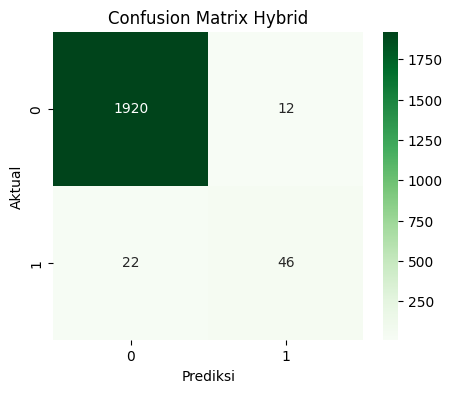

In [30]:
# EVALUASI MODEL
print("\n📊 Evaluasi Model Hybrid (XGBoost + OCSVM Score):")
y_pred = xgb_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix Hybrid')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

In [31]:
# SIMPAN SEMUA ARTEFAK UNTUK BACKEND
print("\n💾 Menyimpan Paket Model untuk Backend...")

# A. Simpan Ulang OCSVM (Dengan nama standar 'hybrid_' agar backend rapi)
joblib.dump(ocsvm, 'hybrid_ocsvm_model.pkl')
joblib.dump(scaler_ocsvm, 'hybrid_ocsvm_scaler.pkl')
joblib.dump(features_ocsvm, 'hybrid_ocsvm_features.json')
joblib.dump(xgb_model, 'hybrid_xgb_model.pkl')
joblib.dump(scaler_xgb, 'hybrid_xgb_scaler.pkl')
joblib.dump(features_xgb, 'hybrid_xgb_features.json')

print("✅ SELESAI! 6 File 'hybrid_*.pkl/json' telah dibuat.")
print("   Pindahkan file-file ini ke folder backend Anda.")


💾 Menyimpan Paket Model untuk Backend...
✅ SELESAI! 6 File 'hybrid_*.pkl/json' telah dibuat.
   Pindahkan file-file ini ke folder backend Anda.
